<a href="https://colab.research.google.com/github/nevita275/ML_20_Nevita/blob/main/JS09/JS09-Tugas2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NAMA: NEVITA TRIYA YULIANA
# KELAS: TI-3F
# ABSEN: 20 <br><br>


# Approximate Nearest Neighbors (ANN)

# TUGAS LAB 2 <br> <br>

## Langkah 1 - Install Library

In [1]:
!pip install annoy faiss-cpu hnswlib kagglehub

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 7.2 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 18.3 MB/s  0:00:01
  Created wheel for annoy: filename=annoy-1.17.3-cp313-cp313-linux_x86_64.whl size=520035 sha256=55f9cdc01070bacfeb0259fe87a019eacfe0e46ef5c2a343764f9f77ac0145b0
  Stored in directory: /root/.cache/pip/wheels/fc/4e/87/f1f957e7382aa370452cff98276f51686924d5415e449800ed
  Created wheel for hnswlib: filename=hnswlib-0.8.0-cp313-cp313-linux_x86_64.whl size=2679799 sha256=73d5bc0ab8fdfd3ed8ec96bd65f3a2f35c69e8d1b172254294d83305a18c0f93
  Stored in directory: /root/.cache/pip/wheels/35/04/88/b31765a4b9957705e18065db4657e61fc8da54f50

## Langkah 2 - Import dan parameter

In [2]:
import os
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import faiss
import hnswlib
from annoy import AnnoyIndex
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# ---------- Parameter percobaan ----------
K = 10                  # jumlah nearest neighbors
N_SAMPEL = None         # None = seluruh data. Untuk uji coba cepat: 100_000
N_QUERY = 100           # jumlah query acak untuk mengukur waktu dan recall
SEED = 42
JUDUL_QUERY = None      # isi judul lagu (contoh "Shape of You") atau biarkan None = acak

# ---------- Parameter ANN ----------
N_TREES = 20            # ANNOY: jumlah pohon
SEARCH_K = 2000         # ANNOY: jumlah kandidat yang diperiksa saat query
NPROBE = 10             # FAISS IVF: jumlah klaster yang diperiksa saat query
EF_CONSTRUCTION = 100   # HNSW: kualitas pembangunan graf
M = 16                  # HNSW: jumlah koneksi per node
EF_SEARCH = 100         # HNSW: ukuran kandidat saat query

FITUR = ["danceability", "energy", "loudness", "speechiness",
         "acousticness", "instrumentalness", "liveness", "valence", "tempo"]

## Langkah 3 - Ambil dataset

In [3]:
import kagglehub

folder = kagglehub.dataset_download("bwandowando/spotify-songs-with-attributes-and-lyrics")

daftar_csv = sorted(os.path.join(r, f) for r, _, fs in os.walk(folder)
                    for f in fs if f.lower().endswith(".csv"))
for i, p in enumerate(daftar_csv):
    print(i, os.path.basename(p), f"{os.path.getsize(p)/1e6:.0f} MB")

CSV_PATH = daftar_csv[0]   # modul meminta dataset pertama; ganti indeks bila perlu
print("Dipakai:", CSV_PATH)

100%|██████████| 894M/894M [00:11<00:00, 82.0MB/s]

Extracting files...


0 songs_with_attributes_and_lyrics.csv 1545 MB
1 songs_with_lyrics_and_timestamps.csv 2421 MB
Dipakai: /root/.cache/kagglehub/datasets/bwandowando/spotify-songs-with-attributes-and-lyrics/versions/20/songs_with_attributes_and_lyrics.csv


## Langkah 4 - Muat data dan pilih fitur numerik

In [4]:
# Baca nama kolom untuk mendeteksi kolom yang tersedia
kolom_file = pd.read_csv(CSV_PATH, nrows=0).columns.tolist()
print("Kolom di file:", kolom_file)

fitur = [f for f in FITUR if f in kolom_file]
hilang = [f for f in FITUR if f not in kolom_file]
if hilang:
    print("PERINGATAN, fitur tidak ditemukan di file:", hilang)
if len(fitur) == 0:
    raise ValueError("Tidak ada fitur yang cocok. Periksa nama kolom di atas dan sesuaikan FITUR.")

# Deteksi kolom judul dan artis (nama kolom bisa berbeda antar-versi dataset)
kecil = {c.lower(): c for c in kolom_file}
def cari_kolom(kandidat):
    for k in kandidat:
        if k in kecil:
            return kecil[k]
    return None

kol_judul = cari_kolom(["name", "track_name", "song", "title", "track"])
kol_artis = cari_kolom(["artists", "artist", "artist_name", "track_artist"])
print("Kolom judul :", kol_judul)
print("Kolom artis :", kol_artis)

# Hanya muat kolom yang dibutuhkan (lirik tidak ikut dibaca supaya hemat memori)
usecols = fitur + [c for c in (kol_judul, kol_artis) if c]
df = pd.read_csv(CSV_PATH, usecols=usecols)
print("\nBentuk awal:", df.shape)

# Pembersihan: buang baris dengan nilai kosong pada fitur
sebelum = len(df)
df = df.dropna(subset=fitur).reset_index(drop=True)
print(f"Baris dengan nilai kosong dibuang: {sebelum - len(df)}")

# Sampel opsional untuk uji coba cepat
if N_SAMPEL is not None and N_SAMPEL < len(df):
    df = df.sample(N_SAMPEL, random_state=SEED).reset_index(drop=True)
print("Bentuk data dipakai:", df.shape)

display(df.head())
display(df[fitur].describe().round(3))

Kolom di file: ['id', 'name', 'album_name', 'artists', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms', 'lyrics']
Kolom judul : name
Kolom artis : artists

Bentuk awal: (955320, 11)
Baris dengan nilai kosong dibuang: 0
Bentuk data dipakai: (955320, 11)


,name,artists,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,!,HELLYEAH,0.415,0.6050,-11.157,0.0575,0.00116,0.838000,0.4710,0.193,100.059
1,!!,Yxngxr1,0.788,0.6480,-9.135,0.3150,0.90000,0.000000,0.1760,0.287,79.998
2,!!! - Interlude,Glowie,0.000,0.0354,-20.151,0.0000,0.90800,0.000000,0.4790,0.000,0.000
3,!!De Repente!!,Rosendo,0.657,0.8820,-6.340,0.0385,0.00740,0.000013,0.0474,0.939,123.588
4,!!De Repente!!,Rosendo,0.659,0.8930,-8.531,0.0411,0.09220,0.000019,0.0534,0.951,123.600


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
count,955320.000,955320.000,955320.000,955320.000,955320.000,955320.000,955320.000,955320.000,955320.000
mean,0.551,0.652,-7.834,0.084,0.283,0.082,0.220,0.488,122.226
std,0.170,0.239,3.792,0.093,0.312,0.213,0.196,0.251,29.536
min,0.000,0.000,-60.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,0.436,0.482,-9.750,0.034,0.012,0.000,0.099,0.282,99.021
50%,0.558,0.687,-7.041,0.048,0.142,0.000,0.137,0.477,120.661
75%,0.675,0.857,-5.148,0.088,0.518,0.009,0.285,0.690,140.094
max,0.993,1.000,4.882,0.966,0.996,1.000,1.000,1.000,246.130


## Langkah 5 - Standarisasi dengan StandardScaler

In [5]:
X = df[fitur].values.astype("float32")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X).astype("float32")

print("Bentuk X_scaled:", X_scaled.shape)
print("Rata-rata per fitur (harusnya ~0):", X_scaled.mean(axis=0).round(3))
print("Std per fitur (harusnya ~1)      :", X_scaled.std(axis=0).round(3))

N, D = X_scaled.shape

Bentuk X_scaled: (955320, 9)
Rata-rata per fitur (harusnya ~0): [ 0.  0.  0. -0. -0.  0.  0.  0. -0.]
Std per fitur (harusnya ~1)      : [1. 1. 1. 1. 1. 1. 1. 1. 1.]


## Langkah 6 - Bangun keempat index (Exact NN, ANNOY, FAISS, HNSW)

In [6]:
build_time = {}

# 1) Exact NN (brute force, sklearn)
t0 = time.time()
nn = NearestNeighbors(n_neighbors=K + 1, algorithm="brute", metric="euclidean").fit(X_scaled)
build_time["Exact NN"] = time.time() - t0
print(f"Exact NN        : build {build_time['Exact NN']:.3f} s")

# 2) ANNOY
t0 = time.time()
annoy_idx = AnnoyIndex(D, "euclidean")
for i in range(N):
    annoy_idx.add_item(i, X_scaled[i])
annoy_idx.build(N_TREES)
build_time["ANNOY"] = time.time() - t0
print(f"ANNOY           : build {build_time['ANNOY']:.3f} s")

# 3) FAISS (IVFFlat, aproksimasi)
nlist = int(min(1000, max(16, np.sqrt(N))))
t0 = time.time()
quantizer = faiss.IndexFlatL2(D)
faiss_idx = faiss.IndexIVFFlat(quantizer, D, nlist)
faiss_idx.train(X_scaled)
faiss_idx.add(X_scaled)
faiss_idx.nprobe = NPROBE
build_time["FAISS (IVFFlat)"] = time.time() - t0
print(f"FAISS (IVFFlat) : build {build_time['FAISS (IVFFlat)']:.3f} s (nlist={nlist})")

# 4) HNSW
t0 = time.time()
hnsw_idx = hnswlib.Index(space="l2", dim=D)
hnsw_idx.init_index(max_elements=N, ef_construction=EF_CONSTRUCTION, M=M)
hnsw_idx.add_items(X_scaled, np.arange(N))
hnsw_idx.set_ef(EF_SEARCH)
build_time["HNSW"] = time.time() - t0
print(f"HNSW            : build {build_time['HNSW']:.3f} s")

Exact NN        : build 0.066 s
ANNOY           : build 30.010 s
FAISS (IVFFlat) : build 1.922 s (nlist=977)
HNSW            : build 96.600 s


## Langkah 7 - Fungsi pencarian untuk tiap metode

In [7]:
# Setiap fungsi mengembalikan (indeks, jarak Euclidean) untuk K+1 tetangga terdekat.
# Catatan: FAISS dan hnswlib mengembalikan jarak KUADRAT, jadi di-sqrt agar setara.
def cari_exact(q):
    d, i = nn.kneighbors(q.reshape(1, -1))
    return i[0], d[0]

def cari_annoy(q):
    i, d = annoy_idx.get_nns_by_vector(q, K + 1, search_k=SEARCH_K, include_distances=True)
    return np.array(i), np.array(d)

def cari_faiss(q):
    d, i = faiss_idx.search(q.reshape(1, -1), K + 1)
    ok = i[0] >= 0
    return i[0][ok], np.sqrt(np.maximum(d[0][ok], 0))

def cari_hnsw(q):
    i, d = hnsw_idx.knn_query(q.reshape(1, -1), k=K + 1)
    return i[0], np.sqrt(np.maximum(d[0], 0))

def buang_diri(idx, dist, q_id):
    """Buang track query itu sendiri dari hasil, lalu ambil K teratas."""
    m = idx != q_id
    return idx[m][:K], dist[m][:K]

METODE = {
    "Exact NN": cari_exact,
    "ANNOY": cari_annoy,
    "FAISS (IVFFlat)": cari_faiss,
    "HNSW": cari_hnsw,
}

## Langkah 8 - Pencarian track terdekat untuk satu lagu

In [8]:
rng = np.random.RandomState(SEED)

# Pilih track query: berdasarkan judul, atau acak jika tidak ketemu
q_id = None
if JUDUL_QUERY and kol_judul:
    cocok = df.index[df[kol_judul].astype(str).str.contains(JUDUL_QUERY, case=False, na=False, regex=False)]
    if len(cocok) > 0:
        q_id = int(cocok[0])
if q_id is None:
    q_id = int(rng.randint(N))

def nama_track(i):
    judul = str(df.loc[i, kol_judul]) if kol_judul else f"track #{i}"
    artis = f" - {df.loc[i, kol_artis]}" if kol_artis else ""
    return judul + artis

print("TRACK QUERY :", nama_track(q_id))
print(df.loc[q_id, fitur].round(3).to_dict())

q = X_scaled[q_id]
tabel_hasil = {}
idx_exact = None
for nama, fn in METODE.items():
    i, d = buang_diri(*fn(q), q_id)
    if nama == "Exact NN":
        idx_exact = set(i)
    tabel_hasil[nama] = pd.DataFrame({
        "Rank": range(1, len(i) + 1),
        "Track": [nama_track(j) for j in i],
        "Jarak": d.round(4),
    })
    irisan = len(set(i) & idx_exact)
    print(f"\n=== {nama} === (irisan dengan Exact NN: {irisan}/{K})")
    display(tabel_hasil[nama])

TRACK QUERY : Caminho das Pedras - Quinteto em Branco e Preto
{'danceability': 0.513, 'energy': 0.567, 'loudness': -11.585, 'speechiness': 0.11, 'acousticness': 0.253, 'instrumentalness': 3.96e-05, 'liveness': 0.162, 'valence': 0.85, 'tempo': 121.937}

=== Exact NN === (irisan dengan Exact NN: 10/10)


,Rank,Track,Jarak
0,1,A Foggy Day - The George Benson Quartet,0.5737
1,2,Up The Junction - Squeeze,0.7033
2,3,Spirit in the Dark (with The Dixie Flyers) - 2...,0.7153
3,4,A Foggy Day - The George Benson Quartet,0.7551
4,5,Rock with Me - Aretha Franklin,0.7563
5,6,Rock-A-Bye-Rock - Buddy Holly,0.7667
6,7,Shahbaaz Qalandar - Nusrat Fateh Ali Khan,0.7715
7,8,(It's Just) Your Love - Aretha Franklin,0.7730
8,9,Le rital - Claude Barzotti,0.7823
9,10,Ashtray - Matt Pless,0.7980



=== ANNOY === (irisan dengan Exact NN: 10/10)


,Rank,Track,Jarak
0,1,A Foggy Day - The George Benson Quartet,0.5737
1,2,Up The Junction - Squeeze,0.7033
2,3,Spirit in the Dark (with The Dixie Flyers) - 2...,0.7153
3,4,A Foggy Day - The George Benson Quartet,0.7551
4,5,Rock with Me - Aretha Franklin,0.7563
5,6,Rock-A-Bye-Rock - Buddy Holly,0.7667
6,7,Shahbaaz Qalandar - Nusrat Fateh Ali Khan,0.7715
7,8,(It's Just) Your Love - Aretha Franklin,0.7730
8,9,Le rital - Claude Barzotti,0.7823
9,10,Ashtray - Matt Pless,0.7980



=== FAISS (IVFFlat) === (irisan dengan Exact NN: 8/10)


,Rank,Track,Jarak
0,1,A Foggy Day - The George Benson Quartet,0.5737
1,2,Up The Junction - Squeeze,0.7033
2,3,Spirit in the Dark (with The Dixie Flyers) - 2...,0.7153
3,4,A Foggy Day - The George Benson Quartet,0.7551
4,5,Rock-A-Bye-Rock - Buddy Holly,0.7667
5,6,(It's Just) Your Love - Aretha Franklin,0.7730
6,7,Le rital - Claude Barzotti,0.7823
7,8,Ashtray - Matt Pless,0.7980
8,9,Hooked On A Feeling - Toxic Audio,0.8066
9,10,Mal Aimé - Koffi Olomide,0.8193



=== HNSW === (irisan dengan Exact NN: 10/10)


,Rank,Track,Jarak
0,1,A Foggy Day - The George Benson Quartet,0.5737
1,2,Up The Junction - Squeeze,0.7033
2,3,Spirit in the Dark (with The Dixie Flyers) - 2...,0.7153
3,4,A Foggy Day - The George Benson Quartet,0.7551
4,5,Rock with Me - Aretha Franklin,0.7563
5,6,Rock-A-Bye-Rock - Buddy Holly,0.7667
6,7,Shahbaaz Qalandar - Nusrat Fateh Ali Khan,0.7715
7,8,(It's Just) Your Love - Aretha Franklin,0.7730
8,9,Le rital - Claude Barzotti,0.7823
9,10,Ashtray - Matt Pless,0.7980


## Langkah 9 - Perbandingan performa (waktu dan recall)

In [9]:
# Benchmark: N_QUERY track acak sebagai query, waktu query rata-rata dan recall@K
q_ids = rng.choice(N, size=N_QUERY, replace=False)
hasil_idx = {m: [] for m in METODE}
total_waktu = {m: 0.0 for m in METODE}

for qi in q_ids:
    qv = X_scaled[qi]
    for m, fn in METODE.items():
        t0 = time.time()
        i, d = fn(qv)
        total_waktu[m] += time.time() - t0
        hasil_idx[m].append(buang_diri(i, d, qi)[0])

baris = []
for m in METODE:
    recall = np.mean([len(set(hasil_idx[m][j]) & set(hasil_idx["Exact NN"][j])) / K
                      for j in range(N_QUERY)])
    q_ms = total_waktu[m] * 1000 / N_QUERY
    baris.append({"Metode": m,
                  "Build (s)": build_time[m],
                  "Query (ms/query)": q_ms,
                  "Recall@10": recall})

hasil = pd.DataFrame(baris).set_index("Metode")
hasil["Speedup vs Exact"] = hasil.loc["Exact NN", "Query (ms/query)"] / hasil["Query (ms/query)"]
print(f"Jumlah data: {N:,} | Dimensi: {D} | K={K} | Jumlah query: {N_QUERY}")
display(hasil.round(4))

Jumlah data: 955,320 | Dimensi: 9 | K=10 | Jumlah query: 100


,Build (s),Query (ms/query),Recall@10,Speedup vs Exact
Metode,,,,
Exact NN,0.0657,40.6334,1.000,1.0000
ANNOY,30.0096,0.6772,0.996,60.0015
FAISS (IVFFlat),1.9219,0.3996,0.986,101.6776
HNSW,96.6005,1.1467,0.988,35.4342


## Langkah 10 - Grafik perbandingan

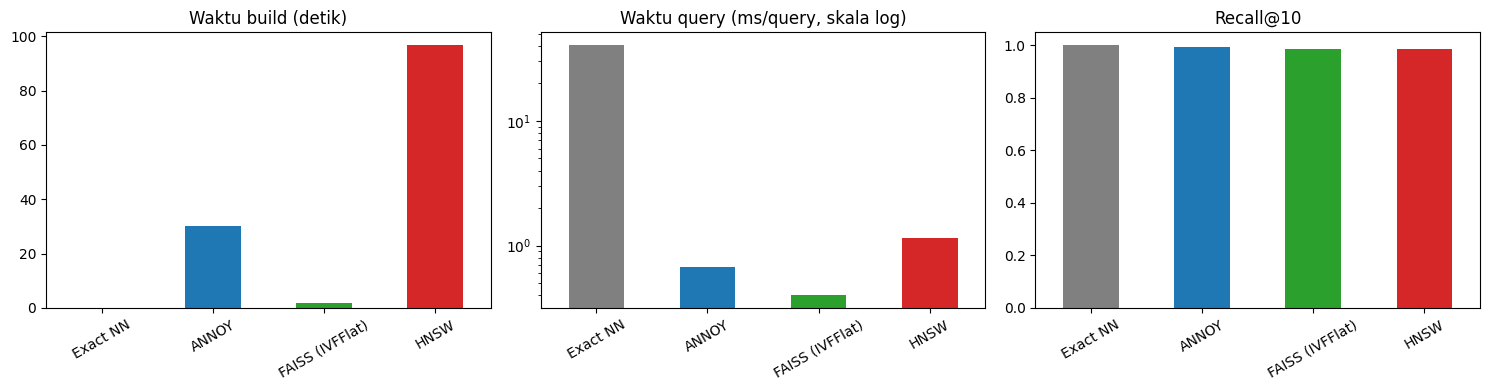

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
warna = ["gray", "tab:blue", "tab:green", "tab:red"]

hasil["Build (s)"].plot.bar(ax=ax[0], color=warna)
ax[0].set_title("Waktu build (detik)")

hasil["Query (ms/query)"].plot.bar(ax=ax[1], color=warna)
ax[1].set_title("Waktu query (ms/query, skala log)")
ax[1].set_yscale("log")

hasil["Recall@10"].plot.bar(ax=ax[2], color=warna)
ax[2].set_title("Recall@10")
ax[2].set_ylim(0, 1.05)

for a in ax:
    a.set_xlabel("")
    a.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

## Analisis

**Data dan pengaturan.** Dataset yang dipakai adalah songs_with_attributes_and_lyrics.csv
(file pertama dari dua dataset) berisi 955.320 lagu tanpa nilai kosong pada fitur.
Dipakai 9 fitur numerik (danceability, energy, loudness, speechiness, acousticness,
instrumentalness, liveness, valence, tempo) yang distandarisasi dengan StandardScaler.
Pencarian dilakukan untuk K=10 tetangga terdekat dengan jarak Euclidean. Parameter:
ANNOY 20 pohon (search_k=2000), FAISS IVFFlat (nlist=977, nprobe=10), dan HNSW (M=16,
ef_construction=100, ef=100). Waktu query dan recall dihitung dari 100 track acak yang
dijalankan satu per satu.

**Pencarian track terdekat.** Untuk query "Caminho das Pedras - Quinteto em Branco e
Preto", Exact NN menemukan tetangga terdekat "A Foggy Day - The George Benson Quartet"
(jarak 0,5737), diikuti "Up The Junction - Squeeze" (0,7033) dan seterusnya sampai
jarak 0,7980 pada peringkat ke-10. ANNOY dan HNSW menghasilkan 10 tetangga yang sama
persis dengan Exact NN (irisan 10/10), sedangkan FAISS IVFFlat beririsan 8/10: dua
tetangga sebenarnya ("Rock with Me - Aretha Franklin" dan "Shahbaaz Qalandar - Nusrat
Fateh Ali Khan") tidak ditemukan dan digantikan dua track lain yang lebih jauh.
Selisih ini sesuai sifat aproksimasi FAISS yang hanya memeriksa 10 dari 977 klaster.
Lagu yang sama ("A Foggy Day") muncul dua kali karena dataset memuat lebih dari satu
baris untuk satu lagu dengan nilai fitur sedikit berbeda.

**Perbandingan performa (rata-rata 100 query).**

| Metode | Build (s) | Query (ms/query) | Recall@10 | Speedup vs Exact |
|---|---|---|---|---|
| Exact NN | 0,066 | 40,633 | 1,000 | 1x |
| ANNOY | 30,010 | 0,677 | 0,996 | 60,0x |
| FAISS (IVFFlat) | 1,922 | 0,400 | 0,986 | 101,7x |
| HNSW | 96,601 | 1,147 | 0,988 | 35,4x |

Exact NN tidak membutuhkan waktu build tetapi harus membandingkan query dengan seluruh
955.320 lagu sehingga query-nya paling lambat (40,6 ms). Ketiga metode ANN menurunkan
waktu query menjadi kurang dari 1,2 ms dengan recall di atas 0,98. FAISS IVFFlat
adalah yang tercepat untuk query (0,400 ms, sekitar 102 kali lebih cepat) dan build
(1,9 detik) dengan recall 0,986. ANNOY memiliki recall tertinggi di antara metode ANN
(0,996) dengan query 0,677 ms (60 kali lebih cepat), tetapi build 30 detik. HNSW
memiliki build paling lama (96,6 detik) dan, pada pengaturan ini, query 1,147 ms dengan
recall 0,988.

**Pembahasan.** Urutan ini bukan kesimpulan umum bahwa HNSW lebih buruk, karena
parameter tiap metode dibuat tetap dan tidak di-tuning. HNSW umumnya dipilih untuk
query yang sangat cepat pada data besar berdimensi tinggi; pada data 9 dimensi ini
ANNOY dan FAISS sudah sangat efektif. Ketiganya menunjukkan trade-off yang sama:
memperbesar parameter pencarian akan menaikkan recall tetapi memperlambat query.

**Keterbatasan.** Parameter ANN tidak di-tuning, waktu query diukur dari satu kali jalan
(dipengaruhi kondisi mesin Colab), kemiripan hanya dihitung dari fitur audio sehingga
tetangga bisa berasal dari genre yang berbeda, dan dataset memuat baris ganda untuk
beberapa lagu.

**Kesimpulan.** Untuk pencarian track serupa pada hampir satu juta lagu, metode ANN
memberi percepatan 35 sampai 100 kali dibanding Exact NN dengan recall di atas 0,98.
FAISS IVFFlat paling cepat, ANNOY paling akurat di antara metode ANN, dan HNSW
membutuhkan waktu build paling lama. Pilihan metode bergantung pada kebutuhan:
kecepatan query, akurasi, atau biaya build.